In [6]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [7]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [8]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [9]:
mask = '01'

In [10]:
ifs = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_land_'+mask+'_1990-2050_30-60N_precip_count_sum.nc')['dry']
ifs = ifs[31:60,:]

In [13]:
#Define the yearly mean temperature change
data_path = Path('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/2020-2050/yearly_tmean_30-60N')
files = sorted([str(f) for f in data_path.glob(f'30-60N_IFS_9-FESOM_5_daily_year_tmean_*.nc')])[:]
ifs_tmean = xr.open_mfdataset(files, engine='netcdf4',combine='by_coords')['2t']
ifs_tmean = ifs_tmean[1:30,:]
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_tmean_land = ifs_tmean.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_tmean_land_mean = ifs_tmean_land.mean(dim='value').load()
ifs_tmean_land_diff = ifs_tmean_land_mean - ifs_tmean_land_mean[0]

In [14]:
print(ifs_tmean_land_diff.min())

<xarray.DataArray '2t' ()>
array(-0.09294523)


## IFS Cycle4

In [15]:
ifs_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_cycle4_land = xr.where(ifs_cycle4_size > 0, 1, 0)
total_cells = ifs_cycle4_land.sum()

percent_ifs_cycle4 = ifs / total_cells * 100  # DataArray of length time
percent_ifs_cycle4_mean = percent_ifs_cycle4.mean(dim='time')
ifs_lin = stats.linregress(ifs_tmean_land_mean,percent_ifs_cycle4_mean)

print(ifs_lin)

LinregressResult(slope=-0.460822814005875, intercept=14.06604521975638, rvalue=-0.7975209946309486, pvalue=2.2208297719483445e-07, stderr=0.06708678042677192, intercept_stderr=0.6008085316694227)


In [16]:
yrs = np.arange(ifs_tmean_land_mean.size)
x_trend = np.polyval(np.polyfit(yrs, ifs_tmean_land_mean.values, 1), yrs)
ifs_lin = stats.linregress(x_trend, percent_ifs_cycle4_mean)
print(ifs_lin)

LinregressResult(slope=-0.4764547925697833, intercept=14.205645296459583, rvalue=-0.7735205247740508, pvalue=8.637359758167991e-07, stderr=0.07512777213723845, intercept_stderr=0.6725935965107154)


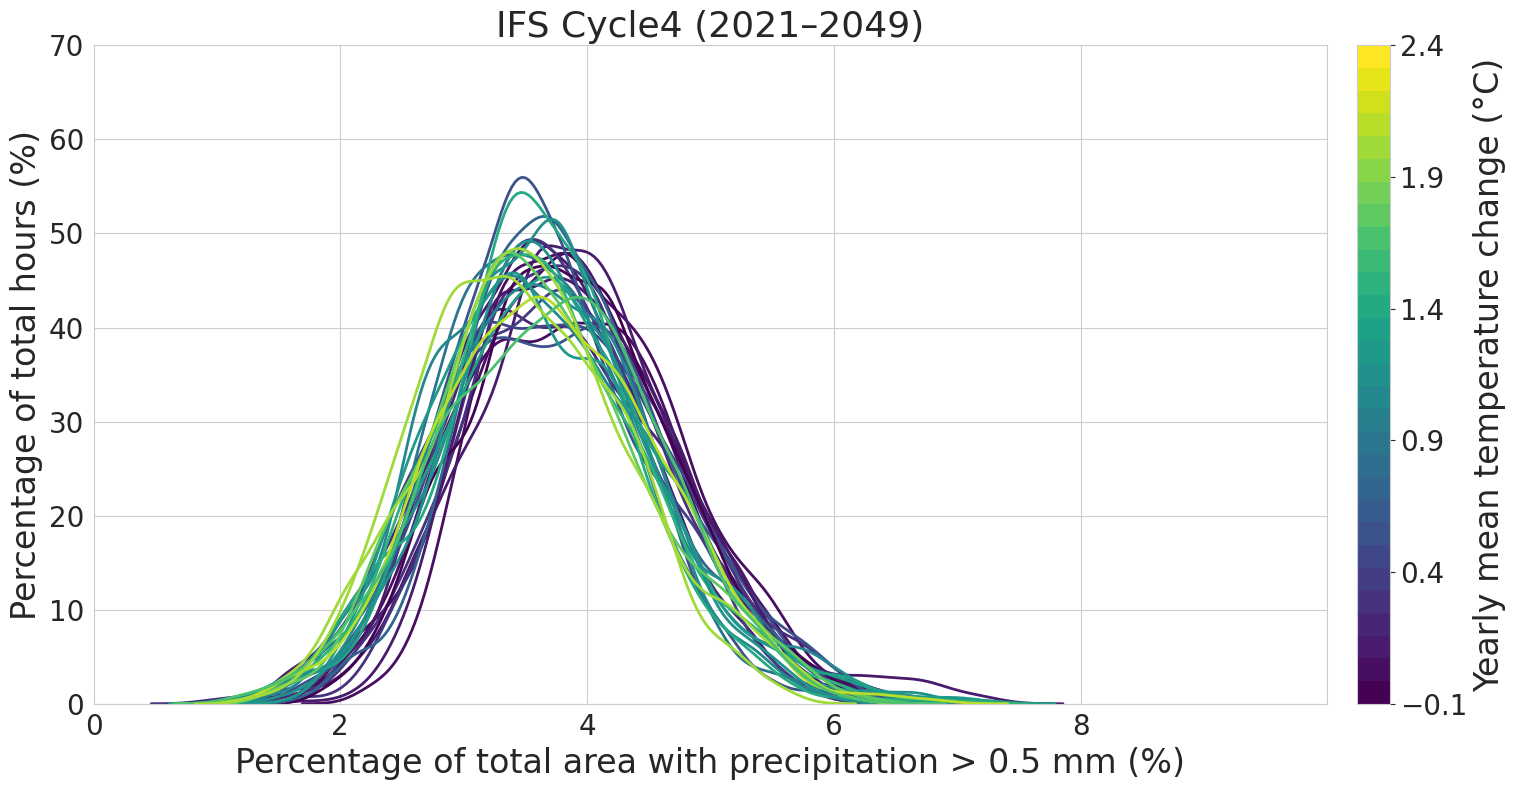

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 0, 25
bin_width = 1.0

# 2) Year indices (0–29) and number of years
years = percent_ifs_cycle4.year.values
n_years = len(years)

# 3) Viridis colormap
temps = ifs_tmean_land_diff.values
cmap = plt.get_cmap('viridis', n_years)

norm = plt.Normalize(
    vmin=-0.1,
    vmax=2.4
)


fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = percent_ifs_cycle4.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])
ticks = np.linspace(-0.1, 2.4, 6)
cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)
# 7) polish & save
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    xmin, xmax = 0, 10
plt.xlim(xmin, xmax)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

ax.set_xlabel(xl, fontsize=24)
ax.set_ylabel('Percentage of total hours (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)

plt.title('IFS Cycle4 (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_IFS_cycle4_histo_precip_coverage_'+mask+'_temp.pdf', format='pdf',bbox_inches='tight')

plt.show()
